### Phase-1:Data Collection and Exploration

In [1]:
#Phase-1:Data Collection and Exploration
import pandas as pd

df = pd.read_excel("C:\\Users\\DELL\\Downloads\\online+retail\\dataset.xlsx")
#First 5 rows
print(df.head())
#Shape
print(df.shape) #After Removing Duplicates -> (536641, 8)
#Features
print(df.columns) #'''Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
                      # 'UnitPrice', 'CustomerID', 'Country'],
                       # dtype='object')'''
#DataTypes
print(df.info())
print()

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
(541909, 8)
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')
<class 'pandas.core.frame.DataFram

In [2]:
#Calculating Null Values in the dataset
print(df.isnull().sum())
df = df.drop_duplicates()
print(df.isnull().sum())


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [3]:
#Adding a Revenue Column -> Quantity * Unit Price
df['Revenue'] = df['Quantity'] * df['UnitPrice']
print(df[['Revenue','Quantity','UnitPrice']].head())
total_revenue = df['Revenue'].sum()
print("Total Revenue is:",total_revenue)

   Revenue  Quantity  UnitPrice
0    15.30         6       2.55
1    20.34         6       3.39
2    22.00         8       2.75
3    20.34         6       3.39
4    20.34         6       3.39
Total Revenue is: 9726006.953999998


In [4]:

# Identify cancelled invoices
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
# Keep valid sales transactions
sales_df = df[
    (~cancelled) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()
print(sales_df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  


### Phase-2 Product Analysis

Top 10 Products are:
 Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


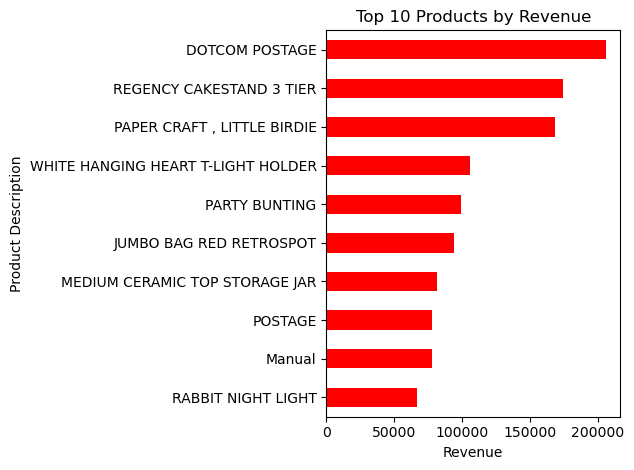

Lowest Performing Products:
 Description
PADS TO MATCH ALL CUSHIONS             0.003
HEN HOUSE W CHICK IN NEST              0.420
SET 12 COLOURING PENCILS DOILEY        0.650
VINTAGE BLUE TINSEL REEL               0.840
PINK CRYSTAL GUITAR PHONE CHARM        0.850
CAT WITH SUNGLASSES BLANK CARD         0.950
HAPPY BIRTHDAY CARD TEDDY/CAKE         0.950
60 GOLD AND SILVER FAIRY CAKE CASES    1.100
SET 36 COLOURING PENCILS DOILEY        1.250
PACK 4 FLOWER/BUTTERFLY PATCHES        1.250
Name: Revenue, dtype: float64


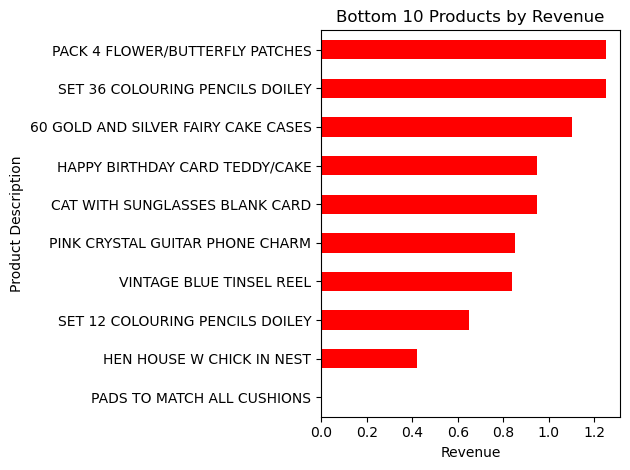

In [5]:
#Phase-2
#Identifying the top 10 products with highest sales
top_10 = sales_df.groupby("Description")['Revenue'].sum().sort_values(ascending=False).head(10)
print("Top 10 Products are:\n",top_10)
#Visualizing the top 10 products
import matplotlib.pyplot as plt
top_10.sort_values().plot(kind='barh',color='red')
plt.title("Top 10 Products by Revenue")
plt.xlabel('Revenue')
plt.ylabel('Product Description')

plt.tight_layout()
plt.show()

bottom_10 = sales_df.groupby("Description")['Revenue'].sum().sort_values().head(10)
print("Lowest Performing Products:\n",bottom_10)

bottom_10.plot(kind='barh',color='red')
plt.title("Bottom 10 Products by Revenue")
plt.xlabel('Revenue')
plt.ylabel('Product Description')

plt.tight_layout()
plt.show()


### Phase-3:Monthly Sales Trends

          InvoiceDate YearMonth  Revenue
0 2010-12-01 08:26:00   2010-12    15.30
1 2010-12-01 08:26:00   2010-12    20.34
2 2010-12-01 08:26:00   2010-12    22.00
3 2010-12-01 08:26:00   2010-12    20.34
4 2010-12-01 08:26:00   2010-12    20.34
YearMonth
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64


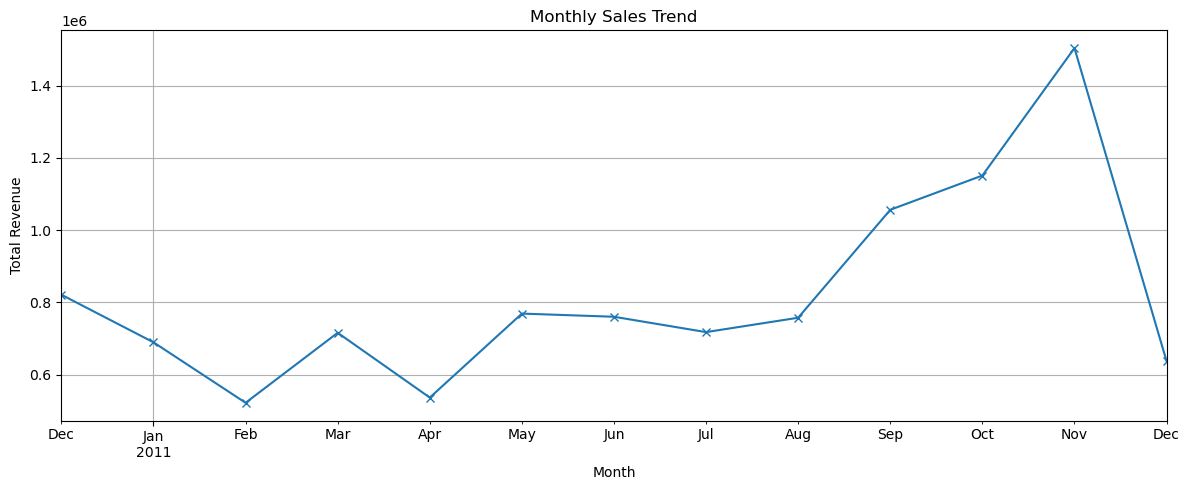

Highest Revenue Month: 2011-11
Highest Revenue: 1503866.78
Lowest Revenue Month: 2011-02
Lowest Revenue: 522545.56


In [6]:
#Phase-3
#Monthly Sales Trends
##Business question2: Which months generate the highest revenue?
sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

sales_df["YearMonth"] = sales_df["InvoiceDate"].dt.to_period("M")

print(sales_df[["InvoiceDate", "YearMonth", "Revenue"]].head())

#Groups 
monthly_sales = sales_df.groupby("YearMonth")["Revenue"].sum()

print(monthly_sales)
#Visualizing Monthly Sales
monthly_sales.plot(kind='line', figsize=(12,5), marker='x')

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.grid(True)

plt.tight_layout()
plt.show()

#Analzing highest months and lowest months
highest_month = monthly_sales.idxmax()
lowest_month = monthly_sales.idxmin()

print("Highest Revenue Month:", highest_month)
print("Highest Revenue:", monthly_sales.max())

print("Lowest Revenue Month:", lowest_month)
print("Lowest Revenue:", monthly_sales.min())

### Phase-4:Customer Analytics

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64


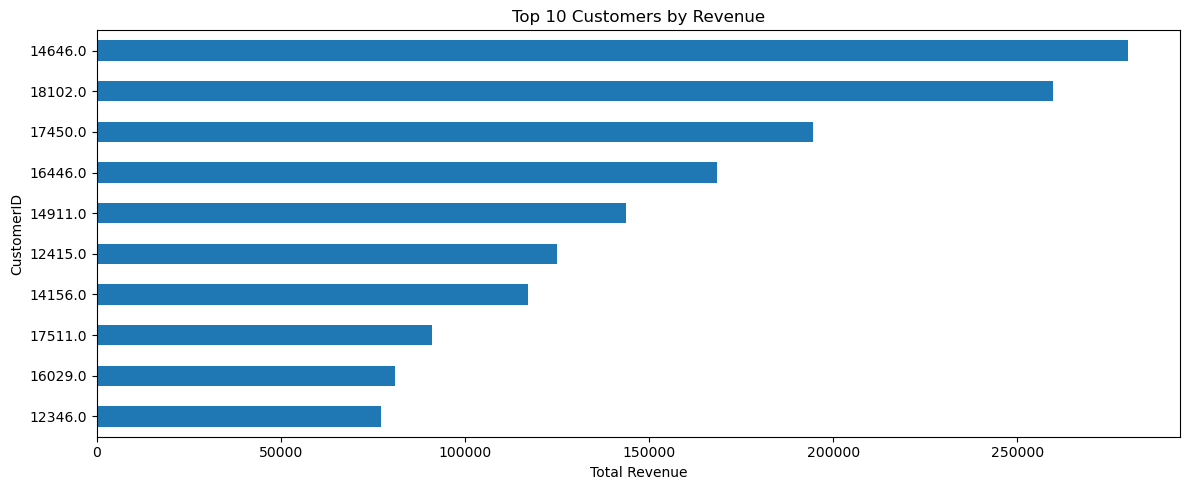

Average Spending 2048.688080682342
Average Spending Customer-by-Customer 2048.688080682342
Customer Orders: CustomerID
12346.0    1
12347.0    7
12348.0    4
12349.0    1
12350.0    1
12352.0    8
12353.0    1
12354.0    1
12355.0    1
12356.0    3
Name: InvoiceNo, dtype: int64
Top 10 Frequent Customers are: CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64
Average Order Value: CustomerID
12346.0    77183.600000
12347.0      615.714286
12348.0      449.310000
12349.0     1757.550000
12350.0      334.400000
12352.0      313.255000
12353.0       89.000000
12354.0     1079.400000
12355.0      459.400000
12356.0      937.143333
dtype: float64


In [7]:
#Phase:4-5:-Customer Analytics
#1Top 10 Customers(Commonly Visiting Customers)
top_10_customers = sales_df.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False).head(10)

print(top_10_customers)

#Visualizing top10 Customers
top_10_customers.sort_values().plot(kind='barh', figsize=(12,5))

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("CustomerID")

plt.tight_layout()
plt.show()

#2Average Spending per customer
average_spending = sales_df.groupby("CustomerID")["Revenue"].sum().mean()
print("Average Spending",average_spending)

average_spending_percustomer = sales_df.groupby("CustomerID")["Revenue"].sum().mean()
print("Average Spending Customer-by-Customer",average_spending_percustomer)

#3 No of Orders by Customer
customer_orders = sales_df.groupby("CustomerID")["InvoiceNo"].nunique()
print("Customer Orders:",customer_orders.head(10))
#4 Top 10 customers by no of orders
top_frequent_customers = customer_orders.sort_values(ascending=False)
print("Top 10 Frequent Customers are:",top_frequent_customers.head(10))
#Average Order Value
customer_aov = sales_df.groupby("CustomerID")["Revenue"].sum()/sales_df.groupby("CustomerID")["InvoiceNo"].nunique()
print("Average Order Value:",customer_aov.head(10))

In [10]:
#Customer Purchase Summary

customer_purchase_summary = pd.DataFrame({"Total_Spending":sales_df.groupby("CustomerID")["Revenue"].sum(),
                                           
                                          "Total_Orders":sales_df.groupby("CustomerID")["InvoiceNo"].nunique()})

customer_purchase_summary["Average_Order_Value"] = customer_purchase_summary["Total_Spending"]/customer_purchase_summary["Total_Orders"]
print(customer_purchase_summary.head(10))

            Total_Spending  Total_Orders  Average_Order_Value
CustomerID                                                   
12346.0           77183.60             1         77183.600000
12347.0            4310.00             7           615.714286
12348.0            1797.24             4           449.310000
12349.0            1757.55             1          1757.550000
12350.0             334.40             1           334.400000
12352.0            2506.04             8           313.255000
12353.0              89.00             1            89.000000
12354.0            1079.40             1          1079.400000
12355.0             459.40             1           459.400000
12356.0            2811.43             3           937.143333


### Phase-5: Customer Segmentation

Recency(R):
 CustomerID
12346.0    326
12347.0      2
12348.0     75
12349.0     19
12350.0    310
12352.0     36
12353.0    204
12354.0    232
12355.0    214
12356.0     23
Name: InvoiceDate, dtype: int64
Frequency(F):
 CustomerID
12346.0    1
12347.0    7
12348.0    4
12349.0    1
12350.0    1
12352.0    8
12353.0    1
12354.0    1
12355.0    1
12356.0    3
Name: InvoiceNo, dtype: int64
Monetary(M):
 CustomerID
12346.0    77183.60
12347.0     4310.00
12348.0     1797.24
12349.0     1757.55
12350.0      334.40
12352.0     2506.04
12353.0       89.00
12354.0     1079.40
12355.0      459.40
12356.0     2811.43
Name: Revenue, dtype: float64
            Recency  Frequency  Monetary R_Score F_Score M_Score R-H-M_Score  \
CustomerID                                                                     
12346.0         326          1  77183.60       1       1       5         115   
12347.0           2          7   4310.00       5       5       5         555   
12348.0          75          4   

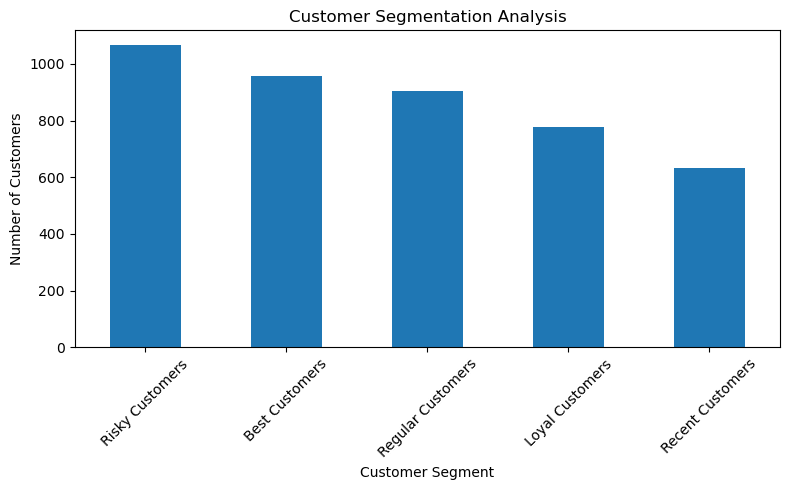

In [18]:
#Phase-5:Customer Segmentation(RFM analysis)
#Recency
reference_date = sales_df["InvoiceDate"].max() + pd.Timedelta(days=1)

recency = ( sales_df.groupby("CustomerID")["InvoiceDate"].max().apply(lambda date:(reference_date - date).days))
print("Recency(R):\n",recency.head(10))

#Frequency
frequency = sales_df.groupby("CustomerID")["InvoiceNo"].nunique()
print("Frequency(F):\n",frequency.head(10))

#Monetary
monetary = sales_df.groupby("CustomerID")["Revenue"].sum()
print("Monetary(M):\n",monetary.head(10))

#Combine R,F,M into one DataFrame

RHM = pd.DataFrame({"Recency":recency,"Frequency":frequency,"Monetary":monetary})

#Assign RFM Scores

RHM["R_Score"] = pd.qcut(RHM["Recency"],5,labels=[5,4,3,2,1])

RHM["F_Score"] = pd.qcut(RHM["Frequency"].rank(method="first"),5,labels=[1,2,3,4,5])

RHM["M_Score"] = pd.qcut(RHM["Monetary"],5,labels=[1,2,3,4,5])

RHM["R-H-M_Score"] = (RHM["R_Score"].astype(str) + RHM["F_Score"].astype(str) + RHM["M_Score"].astype(str) )

def customer_segment(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Best Customers"
    elif row["F_Score"] >= 4:
        return "Loyal Customers"
    elif row["R_Score"] >= 4:
        return "Recent Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Risky Customers"
    else:
        return "Regular Customers"

RHM["Customer_Segment"] = RHM.apply(customer_segment,axis = 1)
print(RHM.head(10))

#Number of segment counts
segment_counts = RHM["Customer_Segment"].value_counts()

print(segment_counts)

#Visualization of segments
segment_counts.plot(kind='bar', figsize=(8,5))

plt.title("Customer Segmentation Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Phase-6:Product Performance Analysis

Top Quantity Products are:
 Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


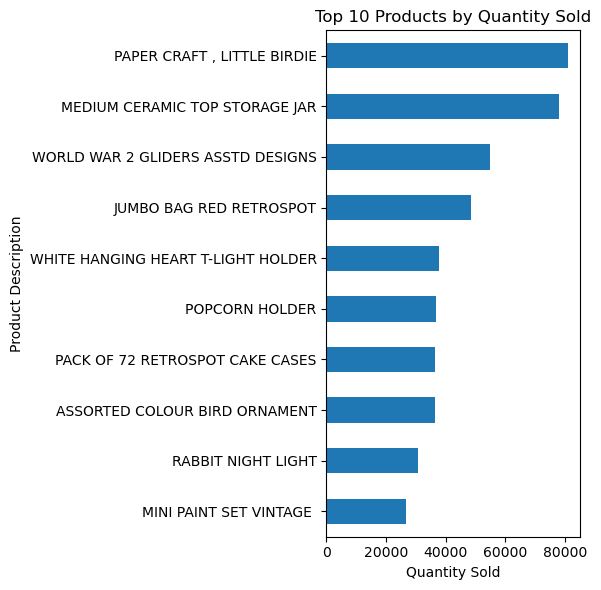

                                 Total_Revenue  Total_Quantity
Description                                                   
4 PURPLE FLOCK DINNER CANDLES           285.70             142
50'S CHRISTMAS GIFT BAG LARGE          2343.63            1915
DOLLY GIRL BEAKER                      2886.25            2451
I LOVE LONDON MINI BACKPACK            1624.02             388
I LOVE LONDON MINI RUCKSACK               4.15               1
NINE DRAWER OFFICE TIDY                 894.42              58
OVAL WALL MIRROR DIAMANTE              2391.12             236
RED SPOT GIFT BAG LARGE                2089.92            1713
SET 2 TEA TOWELS I LOVE LONDON         8082.05            2783
SPACEBOY BABY GIFT SET                 7741.75             498
                                 Total_Revenue  Total_Quantity  \
Description                                                      
4 PURPLE FLOCK DINNER CANDLES           285.70             142   
50'S CHRISTMAS GIFT BAG LARGE          2343.63

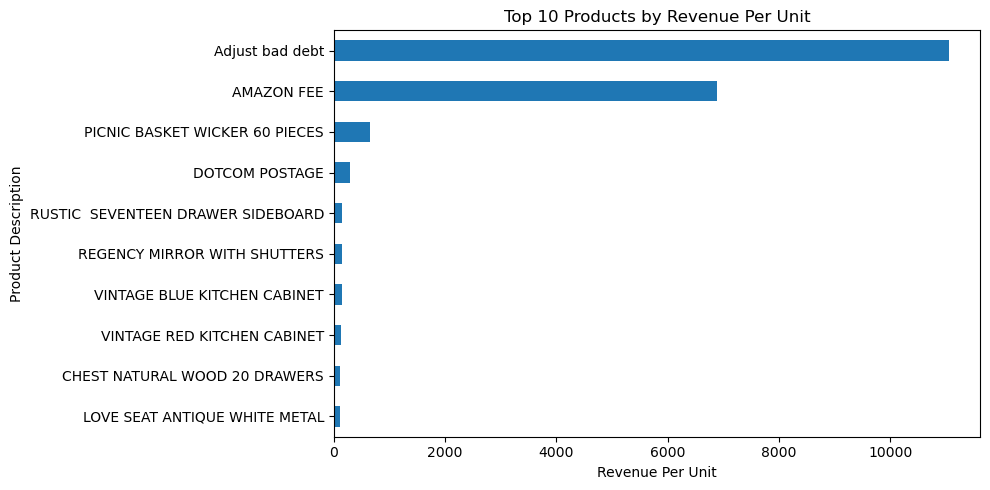

In [31]:
top_quantity_products = sales_df.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)
print("Top Quantity Products are:\n",top_quantity_products)

top_quantity_products.sort_values().plot(kind='barh',figsize=(6,6))
plt.xlabel("Quantity Sold")
plt.ylabel("Product Description")
plt.title("Top 10 Products by Quantity Sold")

plt.tight_layout()
plt.show()

#Revenue vs Quantity
product_comparison = pd.DataFrame({"Total_Revenue":sales_df.groupby("Description")["Revenue"].sum(),
                                    "Total_Quantity":sales_df.groupby("Description")["Quantity"].sum()})
print(product_comparison.head(10))

#High Quantity Low Revenue Products
##Average Revenue Per Unit
product_comparison["Revenue_Per_Unit"] = (
    product_comparison["Total_Revenue"] /
    product_comparison["Total_Quantity"]
)

print(product_comparison.head(10))

top_revenue_per_unit = (
    product_comparison["Revenue_Per_Unit"]
    .sort_values(ascending=False)
    .head(10)
)

print(top_revenue_per_unit)

#Visualization
top_revenue_per_unit.sort_values().plot(
    kind="barh",
    figsize=(10, 5)
)

plt.title("Top 10 Products by Revenue Per Unit")
plt.xlabel("Revenue Per Unit")
plt.ylabel("Product Description")

plt.tight_layout()
plt.show()



### Phase-7:Country Analytics

Revenue generated across countries:
 Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


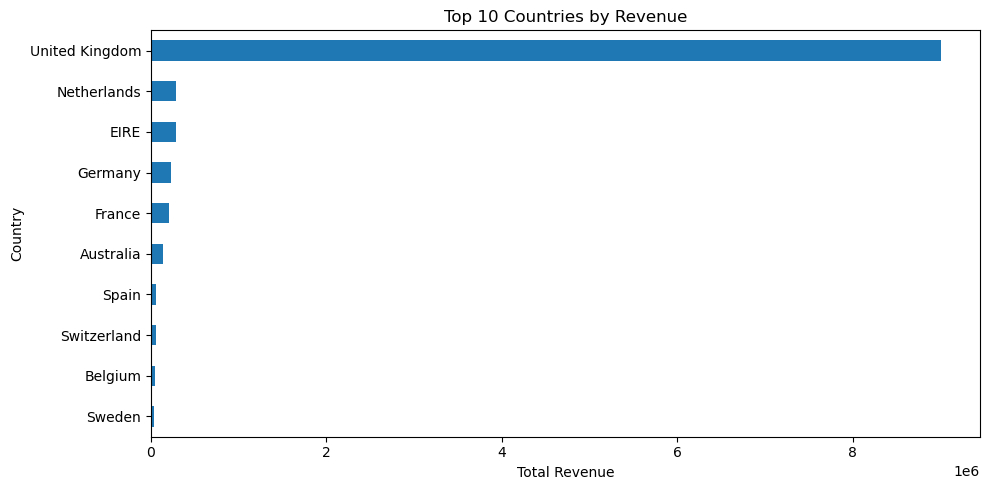

Customers from Different Countries:
 Country
United Kingdom    3920
Germany             94
France              87
Spain               30
Belgium             25
Switzerland         21
Portugal            19
Italy               14
Finland             12
Austria             11
Name: CustomerID, dtype: int64


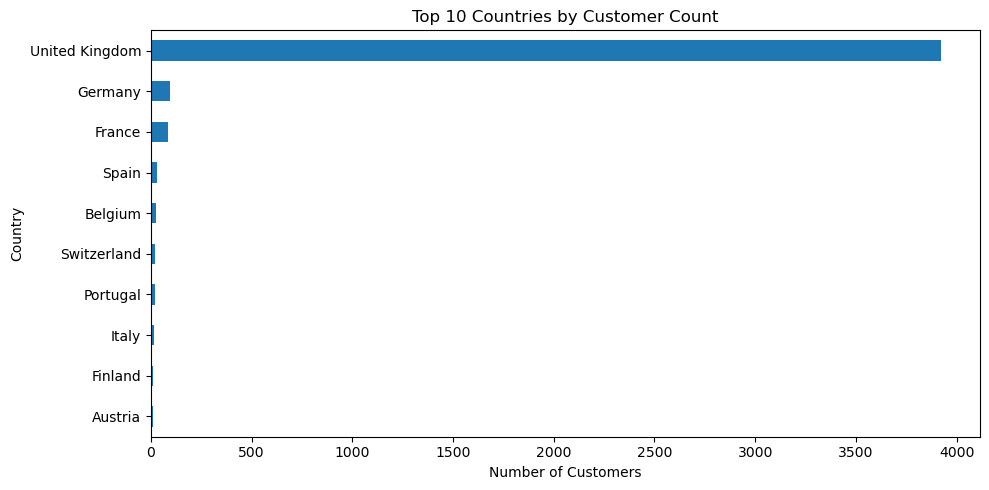

In [33]:
#Revenue According to country
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue generated across countries:\n",country_revenue.head(10))

country_revenue.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 5)
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

#Customers across the world
country_customers = (
    sales_df.groupby("Country")["CustomerID"]
    .nunique()
    .sort_values(ascending=False)
)

print("Customers from Different Countries:\n",country_customers.head(10))

country_customers.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 5)
)

plt.title("Top 10 Countries by Customer Count")
plt.xlabel("Number of Customers")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Phase-8 SQL Analysis

In [44]:
import mysql.connector

conn = mysql.connector.connect(
        host = "localhost",
        user = "root",
        password = "JOSEPHRAJ143@",
        database = "retail_analytics_new"
)
print("Connected to MySQL Successfully")

Connected to MySQL Successfully


In [45]:
sales_df.shape

(524878, 10)

In [52]:
sales_df = sales_df.where(pd.notnull(sales_df),None)
#Checking Columns
sales_df.columns.tolist()
#Convert DataFrame into records

data = [tuple(row) for row in sales_df.itertuples(index=False,name=None)]

cursor = conn.cursor()

sql = """
INSERT INTO retail_sales
(InvoiceNo, StockCode, Description, Quantity, InvoiceDate,
 UnitPrice, CustomerID, Country, Revenue,YearMonth)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s,%s)
"""
sales_df["YearMonth"] = sales_df["YearMonth"].astype(str)
sales_df["InvoiceDate"] = sales_df["InvoiceDate"].astype(str)

batch_size = 10000

for i in range(0,len(data),batch_size):
    batch = data[i:i+batch_size]

    cursor.executemany(sql,batch)
    conn.commit()

    print(f"Inserted{i+len(batch)} rows")

Inserted10000 rows
Inserted20000 rows
Inserted30000 rows
Inserted40000 rows
Inserted50000 rows
Inserted60000 rows
Inserted70000 rows
Inserted80000 rows
Inserted90000 rows
Inserted100000 rows
Inserted110000 rows
Inserted120000 rows
Inserted130000 rows
Inserted140000 rows
Inserted150000 rows
Inserted160000 rows
Inserted170000 rows
Inserted180000 rows
Inserted190000 rows
Inserted200000 rows
Inserted210000 rows
Inserted220000 rows
Inserted230000 rows
Inserted240000 rows
Inserted250000 rows
Inserted260000 rows
Inserted270000 rows
Inserted280000 rows
Inserted290000 rows
Inserted300000 rows
Inserted310000 rows
Inserted320000 rows
Inserted330000 rows
Inserted340000 rows
Inserted350000 rows
Inserted360000 rows
Inserted370000 rows
Inserted380000 rows
Inserted390000 rows
Inserted400000 rows
Inserted410000 rows
Inserted420000 rows
Inserted430000 rows
Inserted440000 rows
Inserted450000 rows
Inserted460000 rows
Inserted470000 rows
Inserted480000 rows
Inserted490000 rows
Inserted500000 rows
Inserted5